# Customer Segmentation and Purchase Pattern Analysis

In [2]:
%pip install pandas numpy matplotlib seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df1 = pd.read_csv("ecommerce_customer_data_large.csv")
df2 = pd.read_csv("ecommerce_customer_data_custom_ratios.csv")
df = pd.concat([df1, df2], ignore_index=True)

df['Purchase Date']=pd.to_datetime(df['Purchase Date'], errors='coerce')
df['Returns']=df['Returns'].fillna(0)
if 'Customer Age' in df.columns:
    df.drop(columns=['Customer Age'], inplace=True)

df['Month']=df['Purchase Date'].dt.month
df['DayOfWeek']=df['Purchase Date'].dt.day_name()
df['Age Group']=pd.cut(df['Age'], bins=[0,20,30,40,50,60,70,100],
labels=['<20','20-30','30-40','40-50','50-60','60-70','70+'])
df.head()

Note: you may need to restart the kernel to use updated packages.


,Customer ID,Purchase Date,Product Category,Product Price,Quantity,Total Purchase Amount,Payment Method,Returns,Customer Name,Age,Gender,Churn,Month,DayOfWeek,Age Group
0,44605,2023-05-03 21:30:02,Home,177,1,2427,PayPal,1.0,John Rivera,31,Female,0,5,Wednesday,30-40
1,44605,2021-05-16 13:57:44,Electronics,174,3,2448,PayPal,1.0,John Rivera,31,Female,0,5,Sunday,30-40
2,44605,2020-07-13 06:16:57,Books,413,1,2345,Credit Card,1.0,John Rivera,31,Female,0,7,Monday,30-40
3,44605,2023-01-17 13:14:36,Electronics,396,3,937,Cash,0.0,John Rivera,31,Female,0,1,Tuesday,30-40
4,44605,2021-05-01 11:29:27,Books,259,4,2598,PayPal,1.0,John Rivera,31,Female,0,5,Saturday,30-40


## Customer Segmentation (RFM)

In [3]:
snapshot_date=df['Purchase Date'].max()+pd.Timedelta(days=1)
rfm=df.groupby('Customer ID').agg({
'Purchase Date':lambda x:(snapshot_date-x.max()).days,
'Customer ID':'count',
'Total Purchase Amount':'sum'
})
rfm.columns=['Recency','Frequency','Monetary']
rfm['Segment']=pd.qcut(rfm['Monetary'],3,labels=['Low Value','Medium Value','High Value'])
rfm.head()

,Recency,Frequency,Monetary,Segment
Customer ID,,,,
1,58,4,9781,Low Value
2,74,9,24469,Medium Value
3,89,12,32010,High Value
4,127,9,16541,Low Value
5,171,13,22293,Low Value


## Customer Segment Distribution

C:\Users\RAC90\AppData\Local\Temp\ipykernel_18800\277897828.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Segment',data=rfm.reset_index(),palette='Set2')


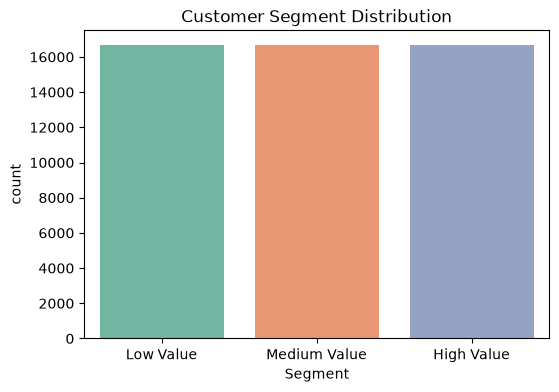

In [4]:
plt.figure(figsize=(6,4))
sns.countplot(x='Segment',data=rfm.reset_index(),palette='Set2')
plt.title('Customer Segment Distribution')
plt.show()

## Segment Profile

In [5]:
segment_profile=rfm.groupby('Segment')[['Recency','Frequency','Monetary']].mean()
segment_profile

C:\Users\RAC90\AppData\Local\Temp\ipykernel_18800\2439636816.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  segment_profile=rfm.groupby('Segment')[['Recency','Frequency','Monetary']].mean()


,Recency,Frequency,Monetary
Segment,,,
Low Value,181.301632,7.039962,17008.524181
Medium Value,128.479810,9.889782,26618.714706
High Value,100.691509,13.071647,38138.061806


## Purchase Pattern Analysis

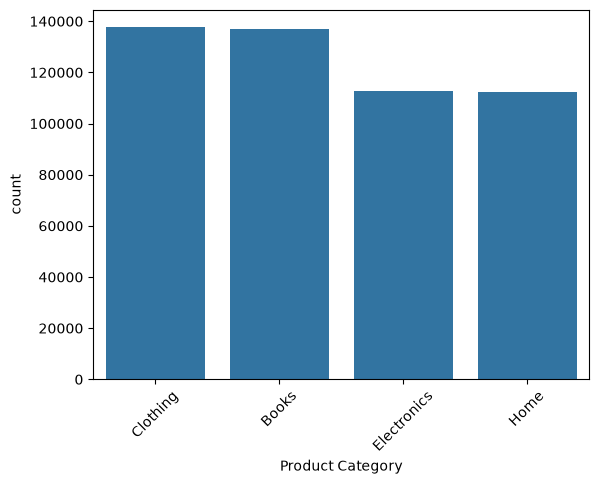

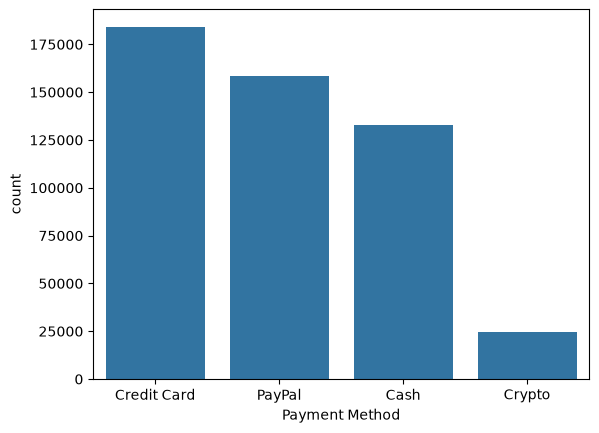

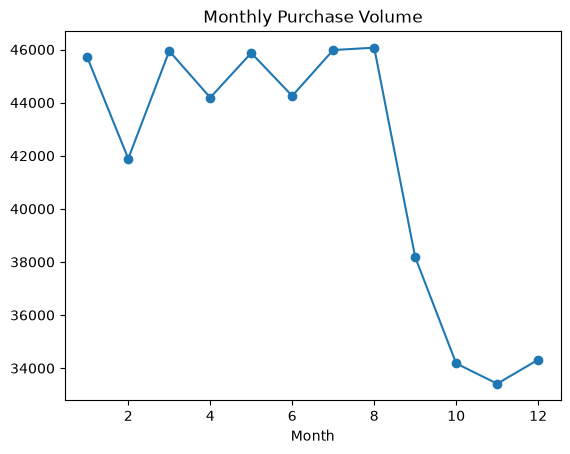

C:\Users\RAC90\AppData\Local\Temp\ipykernel_18800\1687955408.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_spend=df.groupby('Age Group')['Total Purchase Amount'].mean()
C:\Users\RAC90\AppData\Local\Temp\ipykernel_18800\1687955408.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=age_spend.index,y=age_spend.values,palette='coolwarm')


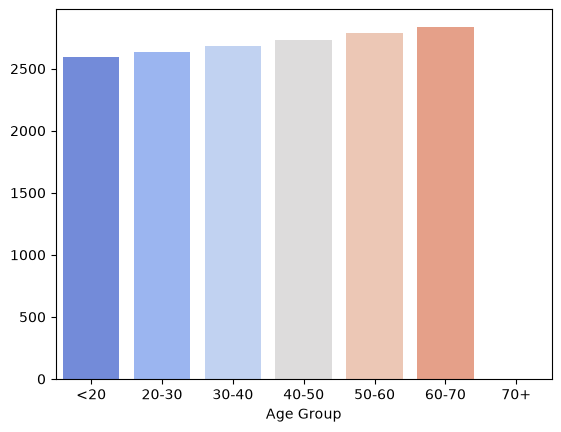

In [6]:
sns.countplot(data=df,x='Product Category',order=df['Product Category'].value_counts().index)
plt.xticks(rotation=45)
plt.show()

sns.countplot(data=df,x='Payment Method',order=df['Payment Method'].value_counts().index)
plt.show()

df.groupby('Month').size().plot(marker='o')
plt.title('Monthly Purchase Volume')
plt.show()

age_spend=df.groupby('Age Group')['Total Purchase Amount'].mean()
sns.barplot(x=age_spend.index,y=age_spend.values,palette='coolwarm')
plt.show()

## Customer Retention Trend

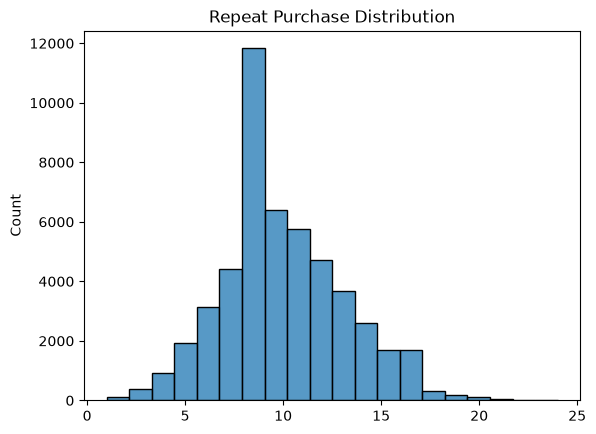

In [7]:
repeat=df.groupby('Customer ID').size()
sns.histplot(repeat,bins=20)
plt.title('Repeat Purchase Distribution')
plt.show()

## Recommendations

1. Reward High-Value Customers through loyalty programs.
2. Re-engage inactive customers using personalized offers.
3. Promote best-selling product categories.
4. Optimize payment methods for customer convenience.
5. Increase cross-selling with product bundles.
